### Preeliminar

In [3]:
# Instalar paquetes científicos y de cálculo con Conda
!conda install -c conda-forge numpy scipy pandas scikit-learn matplotlib seaborn joblib ipykernel jupyter -y
# Instalar librerías de visión y ensamble con pip
!pip install opencv-python xgboost


[WinError 2] The system cannot find the file specified: 'C:\\Users\\Carlos Benitez\\miniconda3\\pkgs\\openssl-3.6.5-hf411b9b_0.conda'
[WinError 2] The system cannot find the file specified: 'C:\\Users\\Carlos Benitez\\miniconda3\\pkgs\\openssl-3.6.5-hf411b9b_0.conda'



3 channel Terms of Service accepted
Retrieving notices: done
Channels:
 - conda-forge
 - defaults
Platform: win-64
Solving environment: done

## Package Plan ##

  environment location: C:\Users\Carlos Benitez\miniconda3\envs\ml

  added / updated specs:
    - ipykernel
    - joblib
    - jupyter
    - matplotlib
    - numpy
    - pandas
    - scikit-learn
    - scipy
    - seaborn


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    ca-certificates-2026.10.23 |       h4c7d964_0         127 KB  conda-forge
    certifi-2026.10.23         |     pyhd8ed1ab_0         132 KB  conda-forge
    cloudpickle-3.1.2          |     pyhcf101f3_1          27 KB  conda-forge
    importlib_resources-7.1.0  |     pyhd8ed1ab_0          34 KB  conda-forge
    ipykernel-7.4.0            |     pyhe2676ad_0         140 KB  conda-forge
    ipywidgets-8.1.9           |     pyhd8ed1ab_0         113 KB  conda-forge
 

WARNING conda.conda_pypi.main:notify_externally_managed_future(156): 
  Did you know? You can install many PyPI packages with conda
  using the conda-pypi beta. Get started:
    https://docs.conda.io/projects/conda/en/stable/new-features.html



In [4]:
import os
import sys
import joblib
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import integrate, optimize

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from xgboost import XGBClassifier

# Detección dinámica y normalizada de la raíz del proyecto
candidates = [
    "D:/Materiales de Auxiliar/2. Machine Learning",
    os.path.abspath("..").replace("\\", "/"),
    os.path.abspath(".").replace("\\", "/")
]
REPO_DIR = None
for c in candidates:
    if os.path.exists(os.path.join(c, "data/processed/gatos")):
        REPO_DIR = c
        break
if REPO_DIR is None:
    REPO_DIR = "D:/Materiales de Auxiliar/2. Machine Learning"

DATA_CSV = os.path.join(REPO_DIR, "data/features_dataset.csv")
MODELS_DIR = os.path.join(REPO_DIR, "models")
PROCESSED_DIR = os.path.join(REPO_DIR, "data/processed")

print(f"Raíz del repositorio: {REPO_DIR}")
print(f"Dataset tabular: {DATA_CSV}")
print(f"Directorio de modelos: {MODELS_DIR}")

Raíz del repositorio: D:/Materiales de Auxiliar/2. Machine Learning
Dataset tabular: D:/Materiales de Auxiliar/2. Machine Learning\data/features_dataset.csv
Directorio de modelos: D:/Materiales de Auxiliar/2. Machine Learning\models


## 1. Carga de Datos y Partición Estratificada

Cargamos la matriz de 349 características visuales y dividimos en:
- **Entrenamiento (80%)**: 288 muestras (144 gatos, 144 perros) para el ajuste de subespacios e hiperparámetros.
- **Prueba Independiente (20%)**: 72 muestras (36 gatos, 36 perros) estrictamente reservadas para la evaluación no sesgada.

In [5]:
# Carga de características
df = pd.read_csv(DATA_CSV)
feature_cols = [c for c in df.columns if c not in ["label", "filename"]]

X = df[feature_cols].values.astype(np.float64)
y_raw = df["label"].values

le = LabelEncoder()
y = le.fit_transform(y_raw) # gatos: 0, perros: 1

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

# Escalado estándar ajustado únicamente sobre entrenamiento
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Dimensiones de entrenamiento: {X_train_scaled.shape}")
print(f"Dimensiones de prueba: {X_test_scaled.shape}")
print(f"Distribución de clases en test: Gatos={np.sum(y_test==0)}, Perros={np.sum(y_test==1)}")

Dimensiones de entrenamiento: (288, 349)
Dimensiones de prueba: (72, 349)
Distribución de clases en test: Gatos=36, Perros=36


## 2. Construcción de Matrices de Clase y Descomposición SVD

Separamos los datos de entrenamiento en dos matrices:
- Matriz de Gatos: $\mathbf{X}_{cat} \in \mathbb{R}^{D \times N_{cat}}$
- Matriz de Perros: $\mathbf{X}_{dog} \in \mathbb{R}^{D \times N_{dog}}$

Calculamos el vector centroide (media) de cada clase:
$$\boldsymbol{\mu}_{cat} = \frac{1}{N_{cat}} \sum_{i=1}^{N_{cat}} \mathbf{x}_i^{(cat)}, \quad \boldsymbol{\mu}_{dog} = \frac{1}{N_{dog}} \sum_{i=1}^{N_{dog}} \mathbf{x}_i^{(dog)}$$

Y restamos la media para obtener las matrices centradas $\mathbf{B}_{cat} = \mathbf{X}_{cat} - \boldsymbol{\mu}_{cat}$ y $\mathbf{B}_{dog} = \mathbf{X}_{dog} - \boldsymbol{\mu}_{dog}$.
Calculamos la SVD económica (`full_matrices=False`):
$$\mathbf{B}_{cat} = \mathbf{U}_{cat} \mathbf{\Sigma}_{cat} \mathbf{V}_{cat}^T, \qquad \mathbf{B}_{dog} = \mathbf{U}_{dog} \mathbf{\Sigma}_{dog} \mathbf{V}_{dog}^T$$

In [6]:
# Matrices en orientación columnas (dimensiones D x N_muestras), idéntico a Clase 8
X_cat_tr = X_train_scaled[y_train == 0].T # (349, 144)
X_dog_tr = X_train_scaled[y_train == 1].T # (349, 144)

mu_cat = X_cat_tr.mean(axis=1, keepdims=True)
mu_dog = X_dog_tr.mean(axis=1, keepdims=True)

B_cat = X_cat_tr - mu_cat
B_dog = X_dog_tr - mu_dog

# SVD económica
U_cat, S_cat, Vt_cat = np.linalg.svd(B_cat, full_matrices=False)
U_dog, S_dog, Vt_dog = np.linalg.svd(B_dog, full_matrices=False)

print(f"B_cat: {B_cat.shape} -> U_cat: {U_cat.shape}, S_cat: {S_cat.shape}")
print(f"B_dog: {B_dog.shape} -> U_dog: {U_dog.shape}, S_dog: {S_dog.shape}")

B_cat: (349, 144) -> U_cat: (349, 144), S_cat: (144,)
B_dog: (349, 144) -> U_dog: (349, 144), S_dog: (144,)


## 3. Curvas de Análisis SVD: Espectro, Energía y Varianza Acumulada
### (Metodología de Clase 8 - Sección 1.1 y 1.2)

Analizamos las tres curvas fundamentales enseñadas en la Clase 8:
1. **Espectro de Valores Singulares $\sigma_k$ (Escala Logarítmica)**:
   Permite visualizar el decaimiento de la magnitud de las componentes principales.
2. **Energía Acumulada**:
   $$\text{Energía}(k) = \frac{\sum_{i=1}^k \sigma_i}{\sum_{i=1}^D \sigma_i}$$
   Con línea de referencia al $90\%$.
3. **Varianza Explicada Acumulada**:
   $$\text{Varianza}(k) = \frac{\sum_{i=1}^k \sigma_i^2}{\sum_{i=1}^D \sigma_i^2}$$
   Con líneas de referencia al $90\%$ y $95\%$.

<>:19: SyntaxWarning: invalid escape sequence '\s'
<>:20: SyntaxWarning: invalid escape sequence '\s'
<>:28: SyntaxWarning: invalid escape sequence '\s'
<>:29: SyntaxWarning: invalid escape sequence '\s'
<>:19: SyntaxWarning: invalid escape sequence '\s'
<>:20: SyntaxWarning: invalid escape sequence '\s'
<>:28: SyntaxWarning: invalid escape sequence '\s'
<>:29: SyntaxWarning: invalid escape sequence '\s'
C:\Users\Carlos Benitez\AppData\Local\Temp\ipykernel_5776\1009518988.py:19: SyntaxWarning: invalid escape sequence '\s'
  axs[1].plot(energy_cat, lw=2, color='#2b5c8f', label='Gatos ($\sum \sigma_i / \sum \sigma$)')
C:\Users\Carlos Benitez\AppData\Local\Temp\ipykernel_5776\1009518988.py:20: SyntaxWarning: invalid escape sequence '\s'
  axs[1].plot(energy_dog, lw=2, color='#d95f02', linestyle='--', label='Perros ($\sum \sigma_i / \sum \sigma$)')
C:\Users\Carlos Benitez\AppData\Local\Temp\ipykernel_5776\1009518988.py:28: SyntaxWarning: invalid escape sequence '\s'
  axs[2].plot(var_cat, 

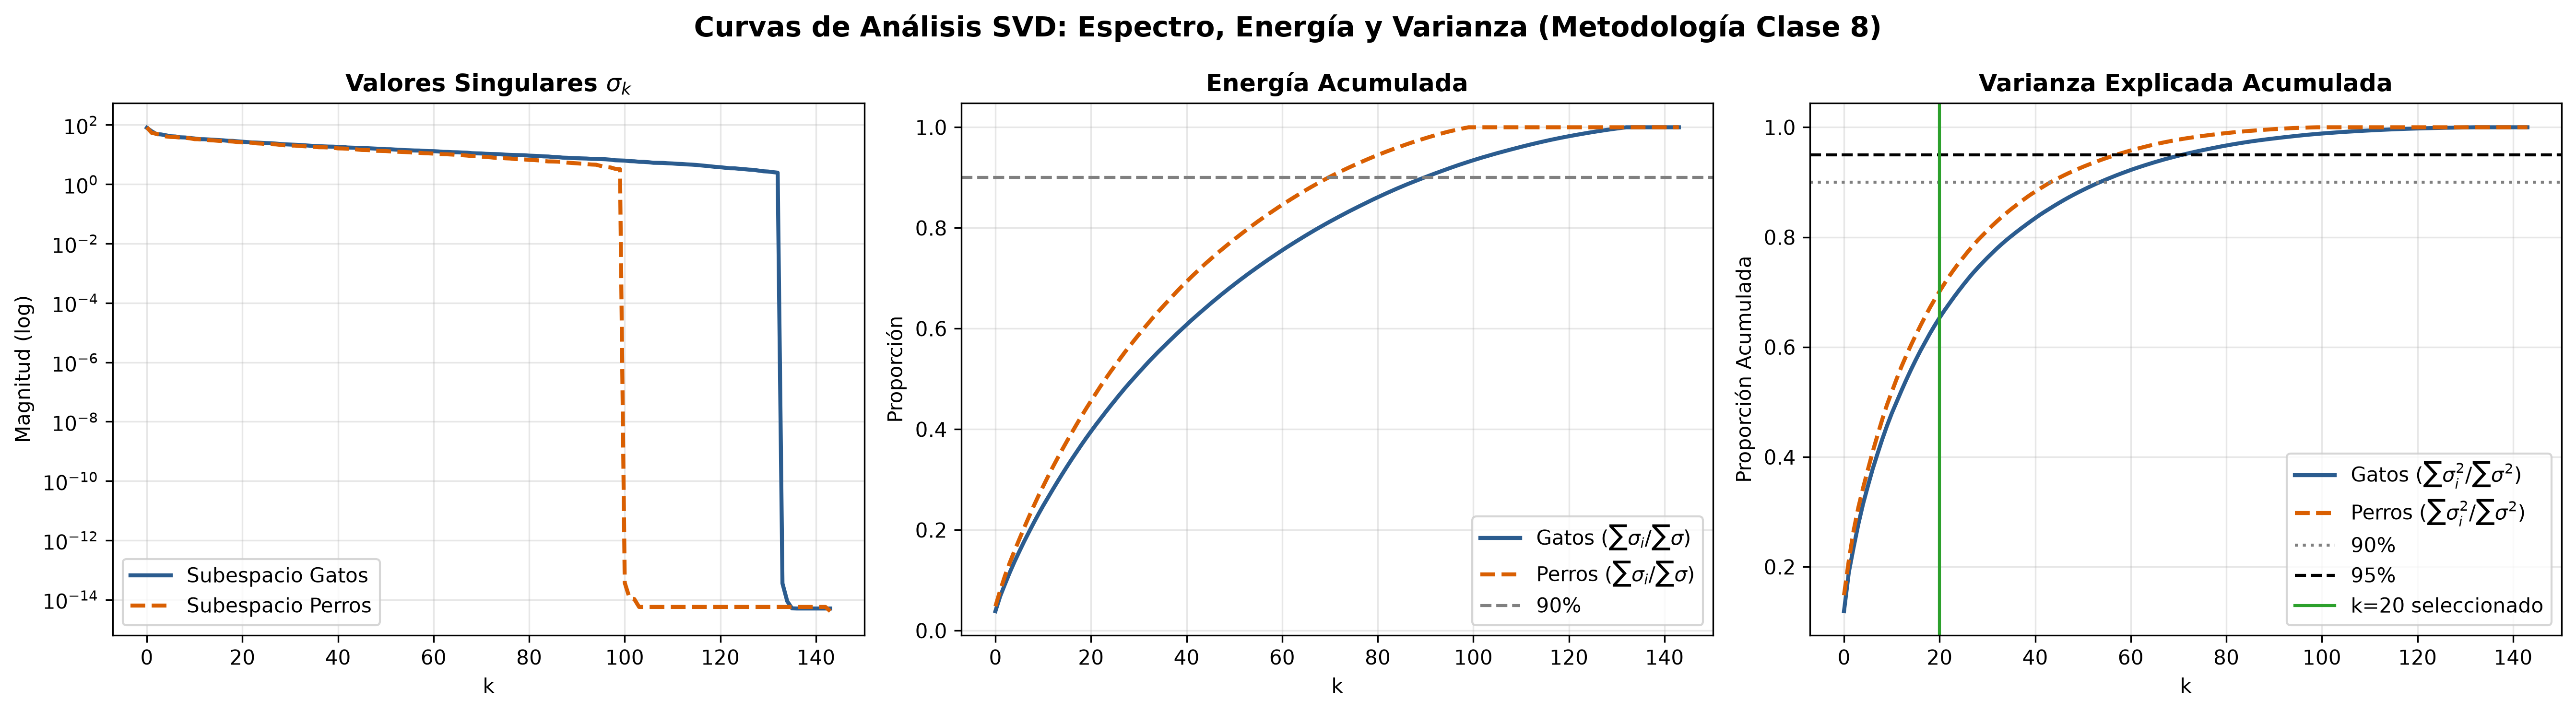

In [7]:
# Cálculo de energía y varianza acumulada
energy_cat = np.cumsum(S_cat) / np.sum(S_cat)
energy_dog = np.cumsum(S_dog) / np.sum(S_dog)

var_cat = np.cumsum(S_cat**2) / np.sum(S_cat**2)
var_dog = np.cumsum(S_dog**2) / np.sum(S_dog**2)

fig, axs = plt.subplots(1, 3, figsize=(18, 5), dpi=300)

# 1. Espectro (escala logarítmica)
axs[0].semilogy(S_cat, lw=2, color='#2b5c8f', label='Subespacio Gatos')
axs[0].semilogy(S_dog, lw=2, color='#d95f02', linestyle='--', label='Subespacio Perros')
axs[0].set_title(r'Valores Singulares $\sigma_k$', fontsize=12, fontweight='bold')
axs[0].set_xlabel('k', fontsize=10); axs[0].set_ylabel('Magnitud (log)', fontsize=10)
axs[0].legend()
axs[0].grid(True, alpha=0.3)

# 2. Energía acumulada (Suma de sigma)
axs[1].plot(energy_cat, lw=2, color='#2b5c8f', label='Gatos ($\sum \sigma_i / \sum \sigma$)')
axs[1].plot(energy_dog, lw=2, color='#d95f02', linestyle='--', label='Perros ($\sum \sigma_i / \sum \sigma$)')
axs[1].axhline(0.9, color='gray', linestyle='--', label='90%')
axs[1].set_title('Energía Acumulada', fontsize=12, fontweight='bold')
axs[1].set_xlabel('k', fontsize=10); axs[1].set_ylabel('Proporción', fontsize=10)
axs[1].legend(loc='lower right')
axs[1].grid(True, alpha=0.3)

# 3. Varianza explicada acumulada (Suma de sigma^2)
axs[2].plot(var_cat, lw=2, color='#2b5c8f', label='Gatos ($\sum \sigma_i^2 / \sum \sigma^2$)')
axs[2].plot(var_dog, lw=2, color='#d95f02', linestyle='--', label='Perros ($\sum \sigma_i^2 / \sum \sigma^2$)')
axs[2].axhline(0.90, color='gray', linestyle=':', label='90%')
axs[2].axhline(0.95, color='black', linestyle='--', label='95%')
axs[2].axvline(20, color='#2ca02c', linestyle='-', lw=1.5, label='k=20 seleccionado')
axs[2].set_title('Varianza Explicada Acumulada', fontsize=12, fontweight='bold')
axs[2].set_xlabel('k', fontsize=10); axs[2].set_ylabel('Proporción Acumulada', fontsize=10)
axs[2].legend(loc='lower right')
axs[2].grid(True, alpha=0.3)

plt.suptitle('Curvas de Análisis SVD: Espectro, Energía y Varianza (Metodología Clase 8)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 4. Truncamiento Óptimo con Ruido Desconocido: Teorema de Gavish-Donoho
### (Metodología de Clase 8 - Sección 1.7)

Cuando una matriz de datos contiene ruido con desviación estándar desconocida, Matan Gavish y David Donoho (2014) demostraron que el umbral óptimo de corte duro $\tau$ para truncar los valores singulares está dado por:

$$\tau = \omega(\beta) \cdot \sigma_{med}$$

donde:
- $\beta = \frac{\min(m, n)}{\max(m, n)}$ es la relación de aspecto de la matriz.
- $\sigma_{med}$ es la mediana empírica de los valores singulares observados.
- $\omega(\beta)$ es una constante analítica derivada de la distribución de Marchenko-Pastur:
  $$\omega(\beta) = \frac{\lambda(\beta)}{\sqrt{\mu_\beta}}, \qquad \lambda(\beta) = \sqrt{2(\beta+1) + \frac{8\beta}{(\beta+1) + \sqrt{\beta^2 + 14\beta + 1}}}$$
  donde $\mu_\beta$ es la mediana de la distribución de cuarto de círculo de Marchenko-Pastur.

Los componentes con $\sigma_k > \tau$ representan **señal morfológica verdadera**, mientras que aquellos por debajo corresponden a **ruido de fondo y texturas espurias**.

Aspect ratio de la matriz beta: 0.4126
Coeficiente omega(beta): 2.0568
Subespacio Gatos: Umbral tau = 21.57 | Rango Optimo r = 31
Subespacio Perros: Umbral tau = 16.75 | Rango Optimo r = 40


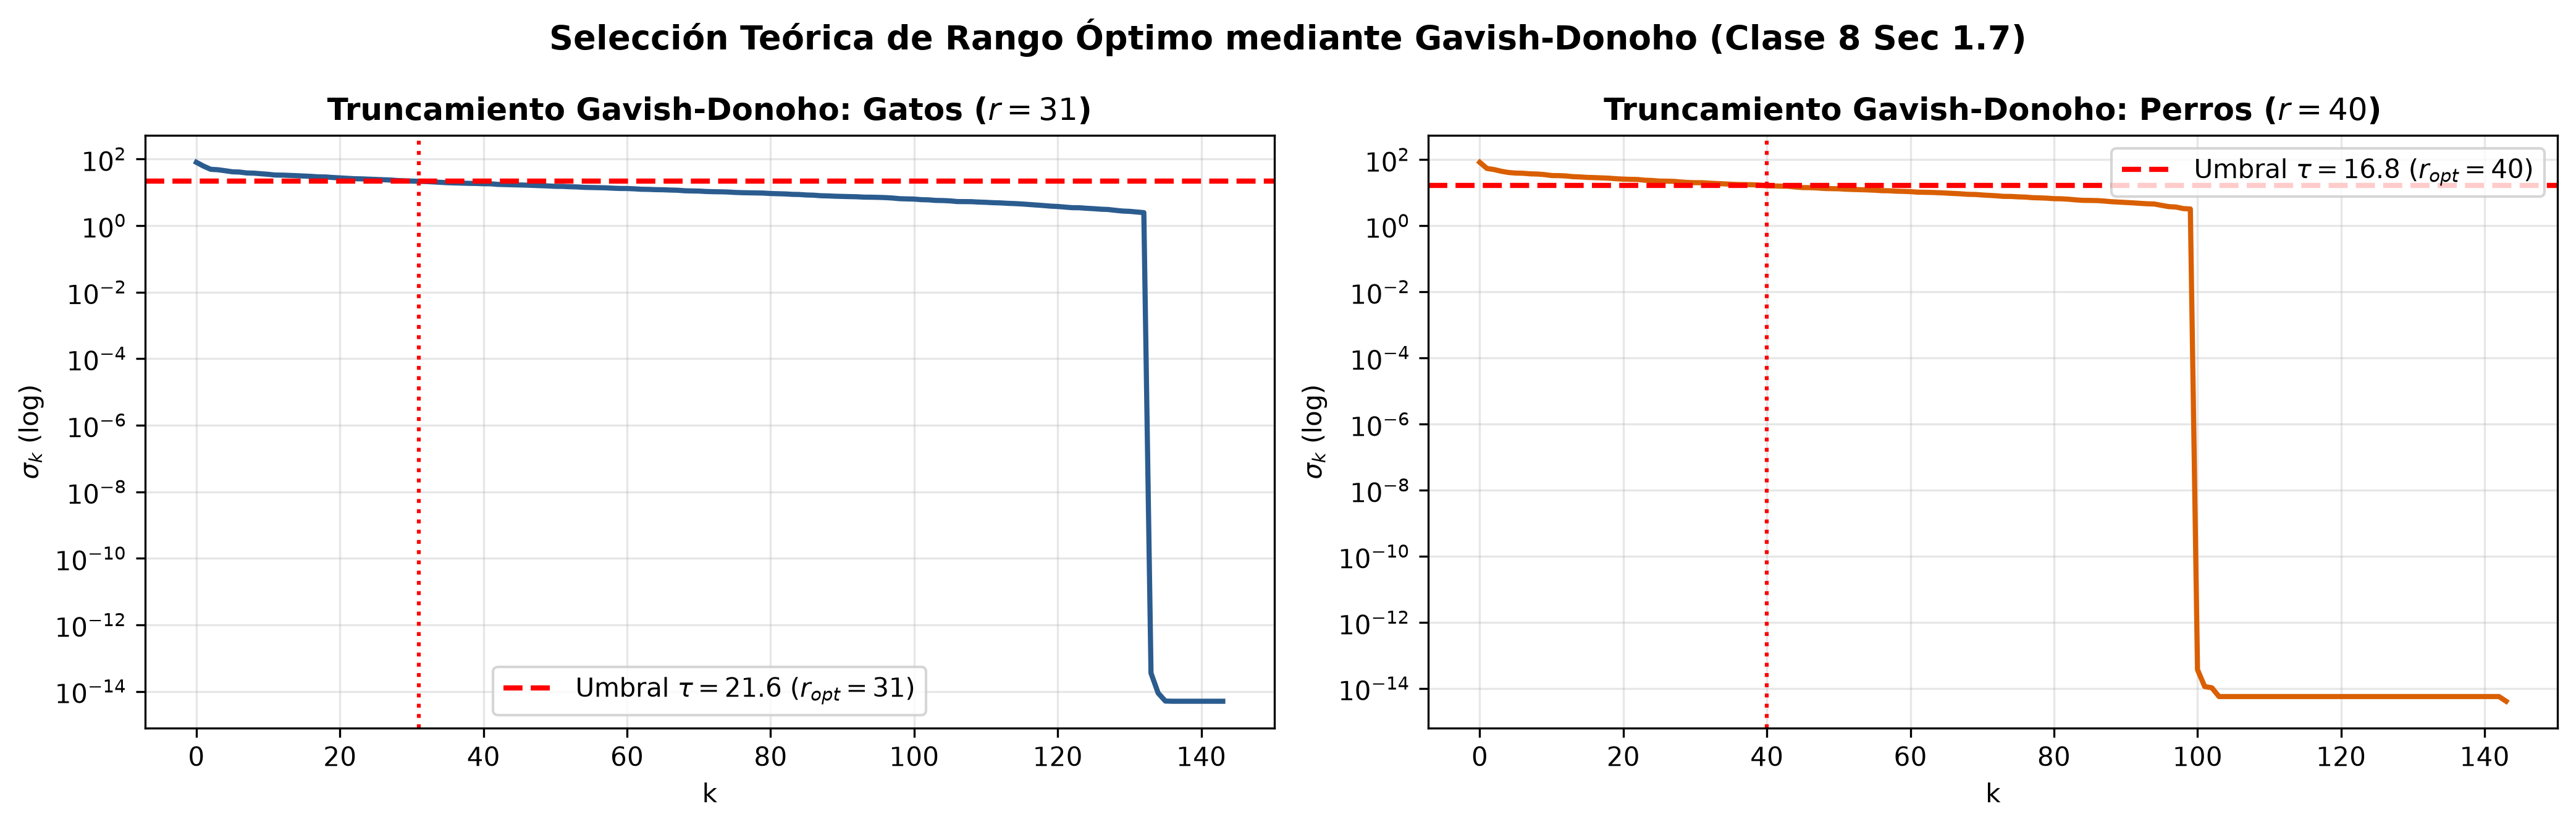

In [8]:
# Implementación exacta de Gavish-Donoho de la Clase 8
def lambda_beta(beta):
    return np.sqrt(2*(beta+1) + 8*beta / ((beta+1) + np.sqrt(beta**2 + 14*beta + 1)))

def omega_beta(beta):
    a = (1 - np.sqrt(beta))**2
    b = (1 + np.sqrt(beta))**2
    f = lambda t: np.sqrt((b-t)*(t-a)) / (2*np.pi*beta*t)
    g = lambda m: integrate.quad(f, a, m)[0] - 0.5
    mu_beta = optimize.brentq(g, a + 1e-9, b - 1e-9)
    return lambda_beta(beta) / np.sqrt(mu_beta)

beta = min(B_cat.shape) / max(B_cat.shape)
w_beta = omega_beta(beta)

tau_cat = w_beta * np.median(S_cat)
tau_dog = w_beta * np.median(S_dog)

r_opt_cat = int(np.sum(S_cat > tau_cat))
r_opt_dog = int(np.sum(S_dog > tau_dog))

print(f"Aspect ratio de la matriz beta: {beta:.4f}")
print(f"Coeficiente omega(beta): {w_beta:.4f}")
print(f"Subespacio Gatos: Umbral tau = {tau_cat:.2f} | Rango Optimo r = {r_opt_cat}")
print(f"Subespacio Perros: Umbral tau = {tau_dog:.2f} | Rango Optimo r = {r_opt_dog}")

# Visualización del umbral de Gavish-Donoho
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5), dpi=300)

axs[0].semilogy(S_cat, color='#2b5c8f', lw=2)
axs[0].axhline(tau_cat, color='red', linestyle='--', lw=2, label=f'Umbral $\\tau={tau_cat:.1f}$ ($r_{{opt}}={r_opt_cat}$)')
axs[0].axvline(r_opt_cat, color='red', linestyle=':', lw=1.5)
axs[0].set_title(f'Truncamiento Gavish-Donoho: Gatos ($r={r_opt_cat}$)', fontsize=12, fontweight='bold')
axs[0].set_xlabel('k'); axs[0].set_ylabel('$\\sigma_k$ (log)')
axs[0].legend(); axs[0].grid(True, alpha=0.3)

axs[1].semilogy(S_dog, color='#d95f02', lw=2)
axs[1].axhline(tau_dog, color='red', linestyle='--', lw=2, label=f'Umbral $\\tau={tau_dog:.1f}$ ($r_{{opt}}={r_opt_dog}$)')
axs[1].axvline(r_opt_dog, color='red', linestyle=':', lw=1.5)
axs[1].set_title(f'Truncamiento Gavish-Donoho: Perros ($r={r_opt_dog}$)', fontsize=12, fontweight='bold')
axs[1].set_xlabel('k'); axs[1].set_ylabel('$\\sigma_k$ (log)')
axs[1].legend(); axs[1].grid(True, alpha=0.3)

plt.suptitle('Selección Teórica de Rango Óptimo mediante Gavish-Donoho (Clase 8 Sec 1.7)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 5. Sweep de Exactitud del Clasificador SVD vs. Rango $r$
### Generación de la Figura Oficial en `models/svd_curva_seleccion_dimension.png`

Evaluamos el desempeño del clasificador de subespacios sobre el conjunto de test para diferentes rangos $r \in [2, 5, 8, 10, 15, 20, 25, 30, 35, 40, 50, 60]$ y consolidamos las 6 curvas de análisis en una única figura de alta calidad.

<>:28: SyntaxWarning: invalid escape sequence '\s'
<>:29: SyntaxWarning: invalid escape sequence '\s'
<>:36: SyntaxWarning: invalid escape sequence '\s'
<>:37: SyntaxWarning: invalid escape sequence '\s'
<>:28: SyntaxWarning: invalid escape sequence '\s'
<>:29: SyntaxWarning: invalid escape sequence '\s'
<>:36: SyntaxWarning: invalid escape sequence '\s'
<>:37: SyntaxWarning: invalid escape sequence '\s'
C:\Users\Carlos Benitez\AppData\Local\Temp\ipykernel_5776\4162818527.py:28: SyntaxWarning: invalid escape sequence '\s'
  axs[0, 1].plot(energy_cat, lw=2, color='#2b5c8f', label='Gatos ($\sum \sigma_k / \sum \sigma$)')
C:\Users\Carlos Benitez\AppData\Local\Temp\ipykernel_5776\4162818527.py:29: SyntaxWarning: invalid escape sequence '\s'
  axs[0, 1].plot(energy_dog, lw=2, color='#d95f02', linestyle='--', label='Perros ($\sum \sigma_k / \sum \sigma$)')
C:\Users\Carlos Benitez\AppData\Local\Temp\ipykernel_5776\4162818527.py:36: SyntaxWarning: invalid escape sequence '\s'
  axs[0, 2].plot(

Figura oficial guardada en: D:/Materiales de Auxiliar/2. Machine Learning\models\svd_curva_seleccion_dimension.png


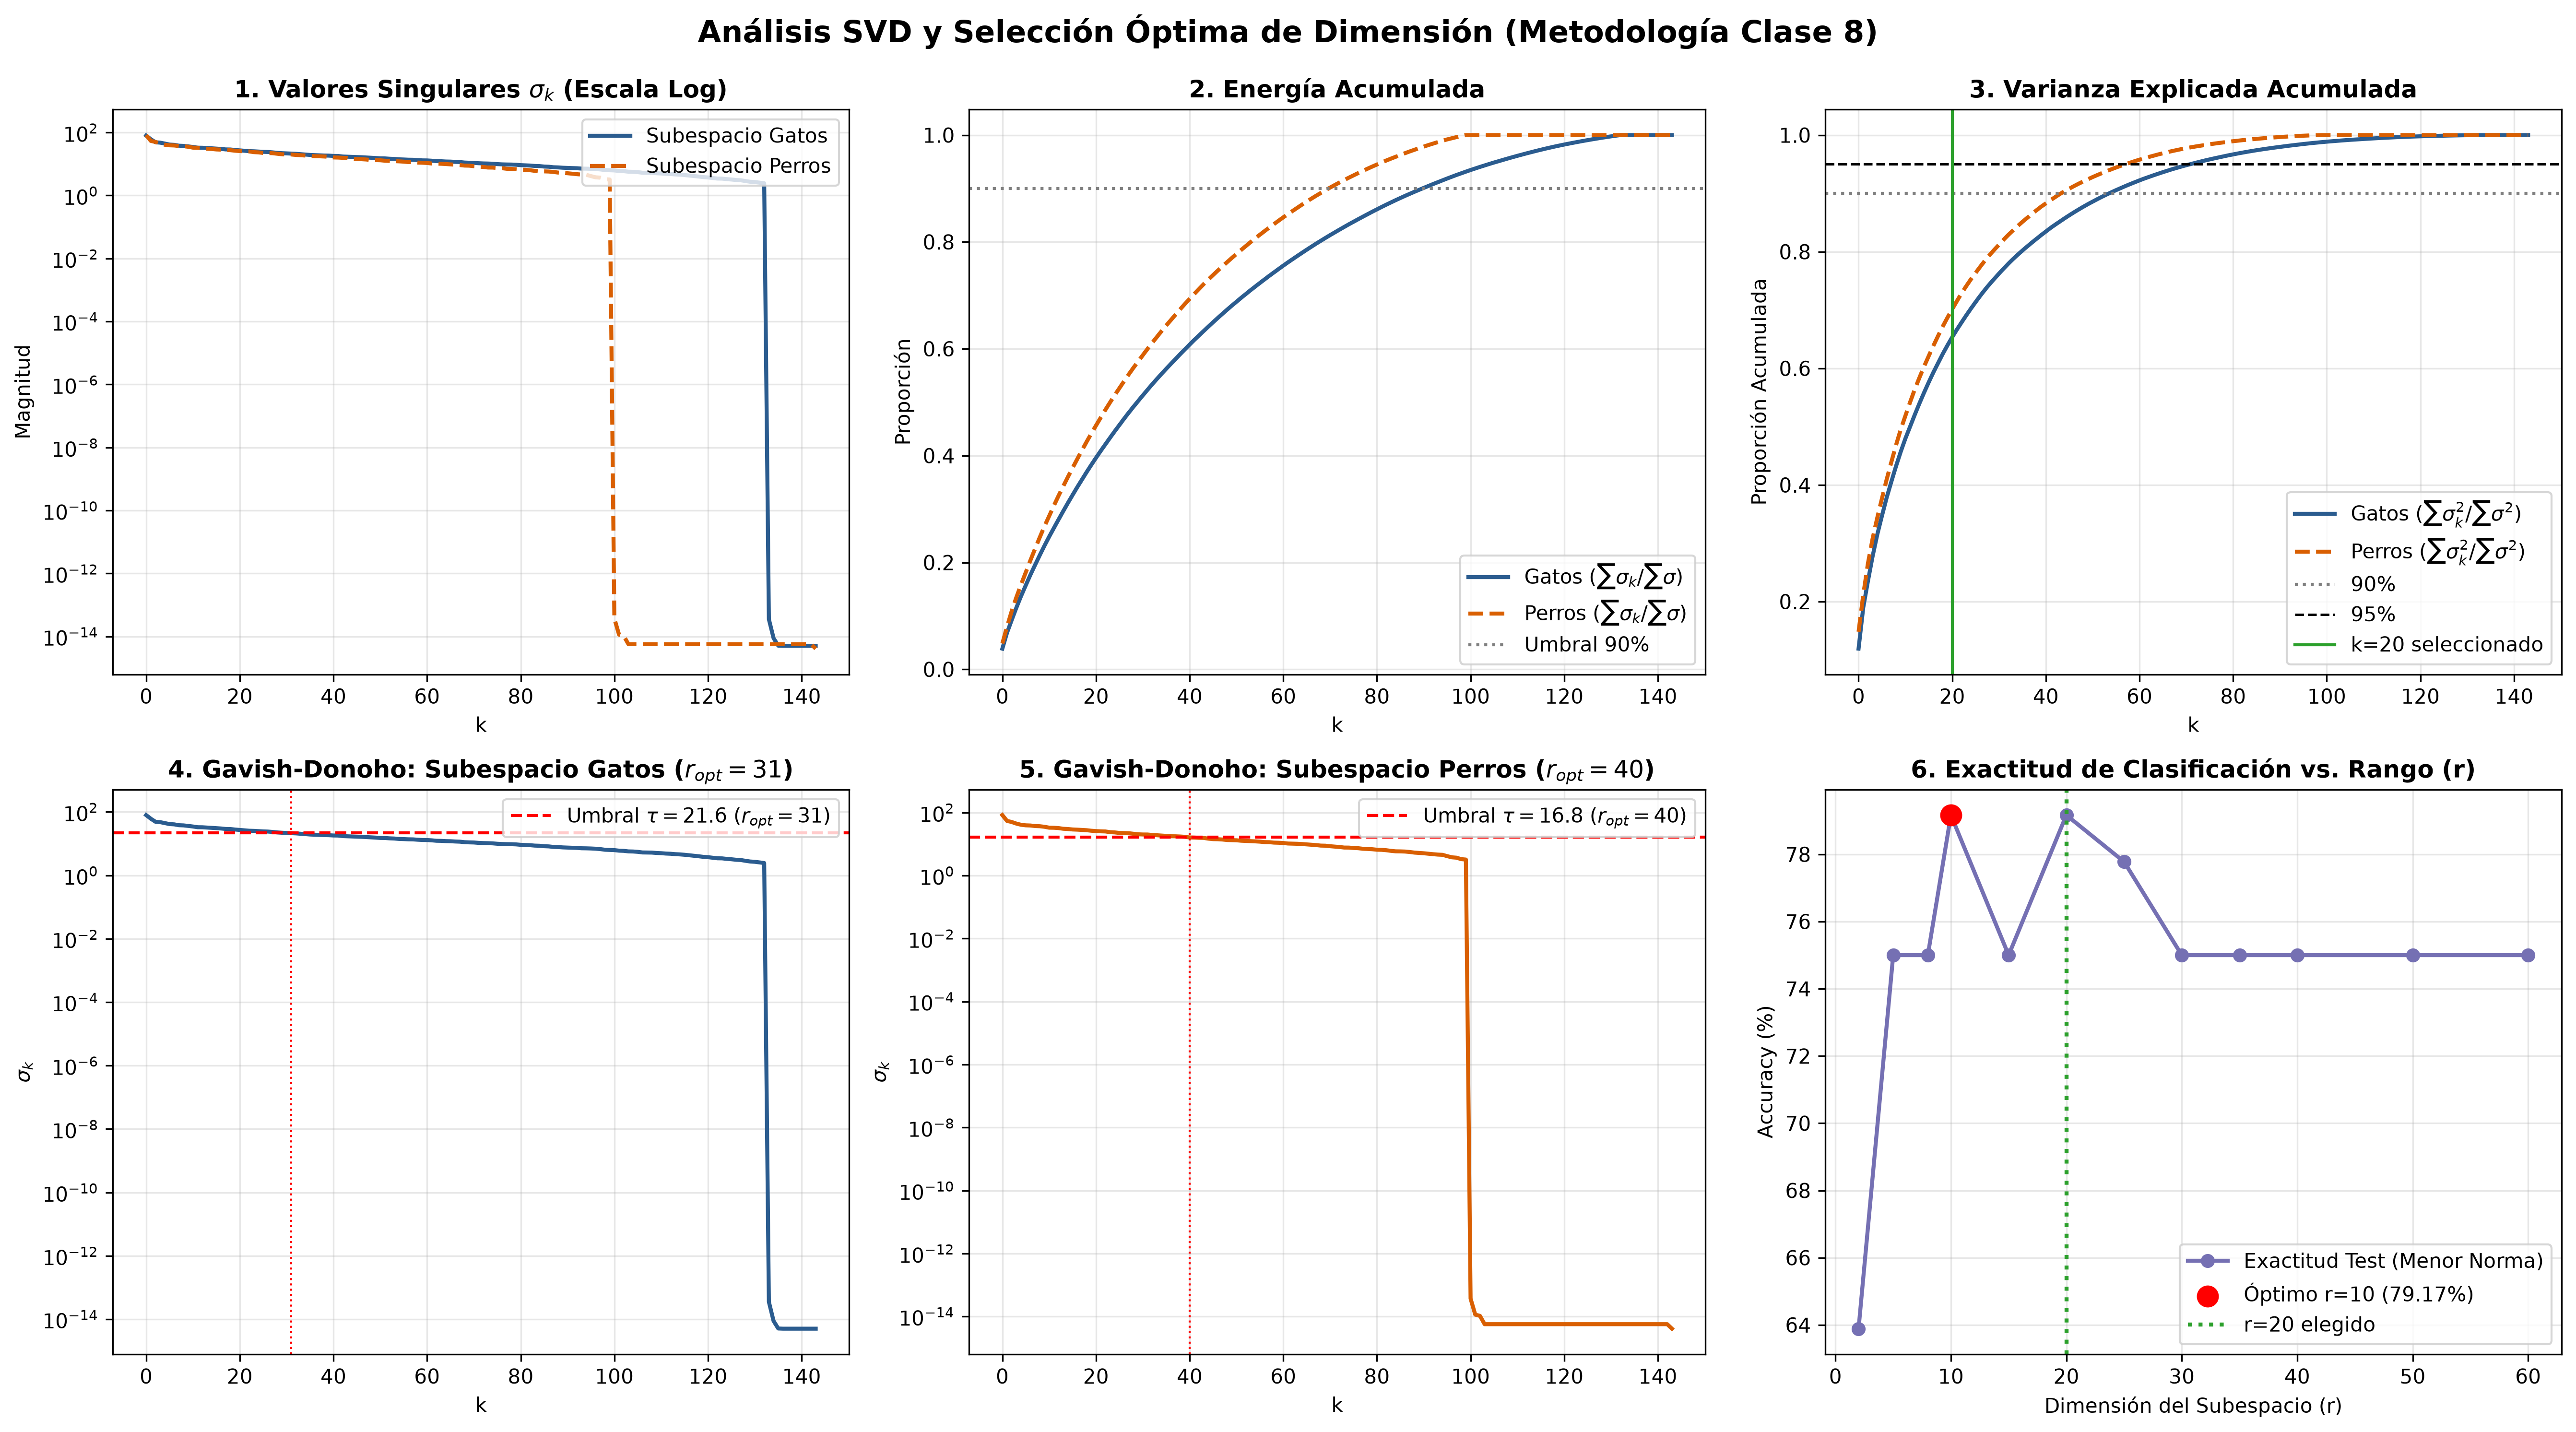

In [9]:
# Sweep de exactitud evaluando rango r
rs = [2, 5, 8, 10, 15, 20, 25, 30, 35, 40, 50, 60]
sweep_accs = []
X_te_cols = X_test_scaled.T # (349, 72)

for r in rs:
    preds = []
    for i in range(X_te_cols.shape[1]):
        z = X_te_cols[:, i:i+1]
        rec_c = mu_cat + U_cat[:, :r] @ (U_cat[:, :r].T @ (z - mu_cat))
        norm_c = np.linalg.norm(z - rec_c)
        rec_d = mu_dog + U_dog[:, :r] @ (U_dog[:, :r].T @ (z - mu_dog))
        norm_d = np.linalg.norm(z - rec_d)
        preds.append(0 if norm_c < norm_d else 1)
    sweep_accs.append(accuracy_score(y_test, preds) * 100)

# Generar figura completa de 6 paneles estilo Clase 8
fig, axs = plt.subplots(2, 3, figsize=(18, 10), dpi=300)

# Panel 1: Espectro
axs[0, 0].semilogy(S_cat, lw=2, color='#2b5c8f', label='Subespacio Gatos')
axs[0, 0].semilogy(S_dog, lw=2, color='#d95f02', linestyle='--', label='Subespacio Perros')
axs[0, 0].set_title(r'1. Valores Singulares $\sigma_k$ (Escala Log)', fontsize=12, fontweight='bold')
axs[0, 0].set_xlabel('k', fontsize=10); axs[0, 0].set_ylabel('Magnitud', fontsize=10)
axs[0, 0].legend(loc='upper right'); axs[0, 0].grid(True, alpha=0.3)

# Panel 2: Energía Acumulada
axs[0, 1].plot(energy_cat, lw=2, color='#2b5c8f', label='Gatos ($\sum \sigma_k / \sum \sigma$)')
axs[0, 1].plot(energy_dog, lw=2, color='#d95f02', linestyle='--', label='Perros ($\sum \sigma_k / \sum \sigma$)')
axs[0, 1].axhline(0.9, color='gray', linestyle=':', lw=1.5, label='Umbral 90%')
axs[0, 1].set_title('2. Energía Acumulada', fontsize=12, fontweight='bold')
axs[0, 1].set_xlabel('k', fontsize=10); axs[0, 1].set_ylabel('Proporción', fontsize=10)
axs[0, 1].legend(loc='lower right'); axs[0, 1].grid(True, alpha=0.3)

# Panel 3: Varianza Explicada Acumulada
axs[0, 2].plot(var_cat, lw=2, color='#2b5c8f', label='Gatos ($\sum \sigma_k^2 / \sum \sigma^2$)')
axs[0, 2].plot(var_dog, lw=2, color='#d95f02', linestyle='--', label='Perros ($\sum \sigma_k^2 / \sum \sigma^2$)')
axs[0, 2].axhline(0.90, color='gray', linestyle=':', lw=1.5, label='90%')
axs[0, 2].axhline(0.95, color='black', linestyle='--', lw=1.2, label='95%')
axs[0, 2].axvline(20, color='#2ca02c', linestyle='-', lw=1.5, label='k=20 seleccionado')
axs[0, 2].set_title('3. Varianza Explicada Acumulada', fontsize=12, fontweight='bold')
axs[0, 2].set_xlabel('k', fontsize=10); axs[0, 2].set_ylabel('Proporción Acumulada', fontsize=10)
axs[0, 2].legend(loc='lower right'); axs[0, 2].grid(True, alpha=0.3)

# Panel 4: Gavish-Donoho Gatos
axs[1, 0].semilogy(S_cat, color='#2b5c8f', lw=2)
axs[1, 0].axhline(tau_cat, color='red', linestyle='--', lw=1.5, label=f'Umbral $\\tau={tau_cat:.1f}$ ($r_{{opt}}={r_opt_cat}$)')
axs[1, 0].axvline(r_opt_cat, color='red', linestyle=':', lw=1)
axs[1, 0].set_title(f'4. Gavish-Donoho: Subespacio Gatos ($r_{{opt}}={r_opt_cat}$)', fontsize=12, fontweight='bold')
axs[1, 0].set_xlabel('k', fontsize=10); axs[1, 0].set_ylabel(r'$\sigma_k$', fontsize=10)
axs[1, 0].legend(loc='upper right'); axs[1, 0].grid(True, alpha=0.3)

# Panel 5: Gavish-Donoho Perros
axs[1, 1].semilogy(S_dog, color='#d95f02', lw=2)
axs[1, 1].axhline(tau_dog, color='red', linestyle='--', lw=1.5, label=f'Umbral $\\tau={tau_dog:.1f}$ ($r_{{opt}}={r_opt_dog}$)')
axs[1, 1].axvline(r_opt_dog, color='red', linestyle=':', lw=1)
axs[1, 1].set_title(f'5. Gavish-Donoho: Subespacio Perros ($r_{{opt}}={r_opt_dog}$)', fontsize=12, fontweight='bold')
axs[1, 1].set_xlabel('k', fontsize=10); axs[1, 1].set_ylabel(r'$\sigma_k$', fontsize=10)
axs[1, 1].legend(loc='upper right'); axs[1, 1].grid(True, alpha=0.3)

# Panel 6: Exactitud vs Rango
best_i = np.argmax(sweep_accs)
axs[1, 2].plot(rs, sweep_accs, marker='o', lw=2, color='#7570b3', label='Exactitud Test (Menor Norma)')
axs[1, 2].scatter([rs[best_i]], [sweep_accs[best_i]], color='red', s=100, zorder=5, label=f'Óptimo r={rs[best_i]} ({sweep_accs[best_i]:.2f}%)')
axs[1, 2].axvline(20, color='#2ca02c', linestyle=':', lw=2, label='r=20 elegido')
axs[1, 2].set_title('6. Exactitud de Clasificación vs. Rango (r)', fontsize=12, fontweight='bold')
axs[1, 2].set_xlabel('Dimensión del Subespacio (r)', fontsize=10); axs[1, 2].set_ylabel('Accuracy (%)', fontsize=10)
axs[1, 2].legend(loc='lower right'); axs[1, 2].grid(True, alpha=0.3)

plt.suptitle('Análisis SVD y Selección Óptima de Dimensión (Metodología Clase 8)', fontsize=15, fontweight='bold', y=0.99)
plt.tight_layout()

curva_out = os.path.join(MODELS_DIR, "svd_curva_seleccion_dimension.png")
plt.savefig(curva_out, bbox_inches='tight')
print(f"Figura oficial guardada en: {curva_out}")
plt.show()

## 6. Animales Medios, Eigen-Animals y Reconstrucción Truncada
### (Metodología de Clase 8 - Sección 1.6 / Eigenfaces)

Visualizamos los vectores singulares izquierdos $\mathbf{U}$ directamente sobre las imágenes $64 \times 64$ para entender geométricamente cómo se reconstruye una muestra de prueba mediante la combinación lineal del animal medio y las primeras componentes principales.

Eigen-Animals guardados en: D:/Materiales de Auxiliar/2. Machine Learning\models\svd_eigen_animals.png


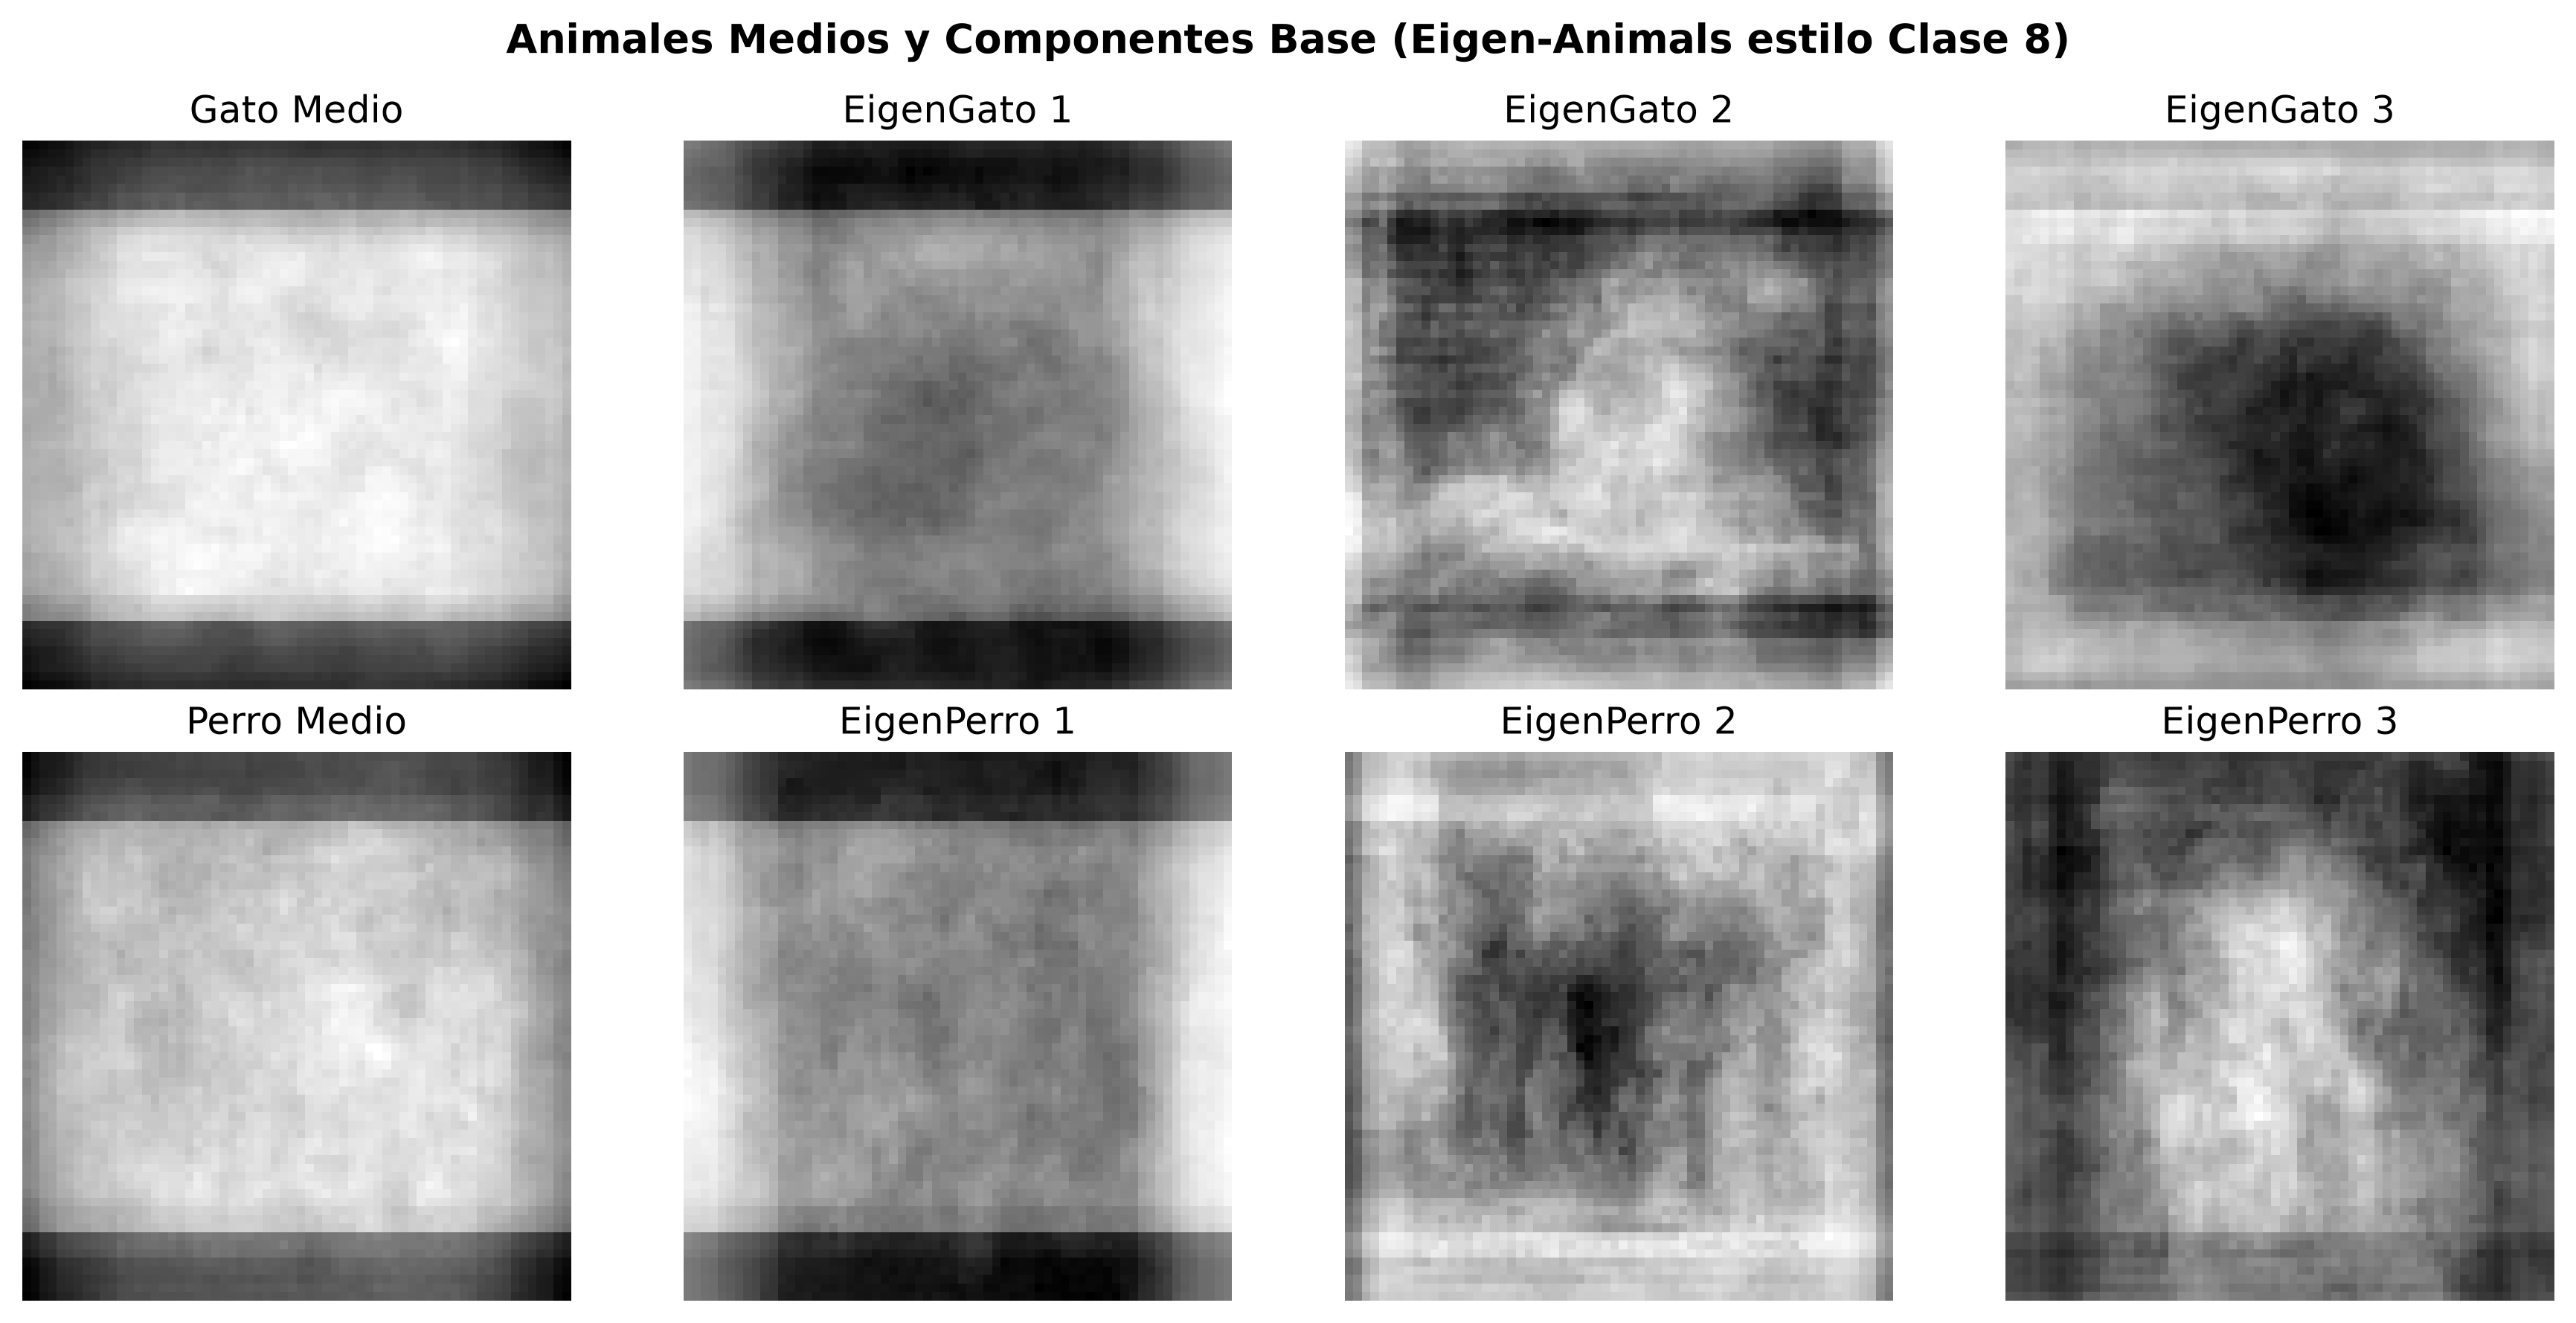

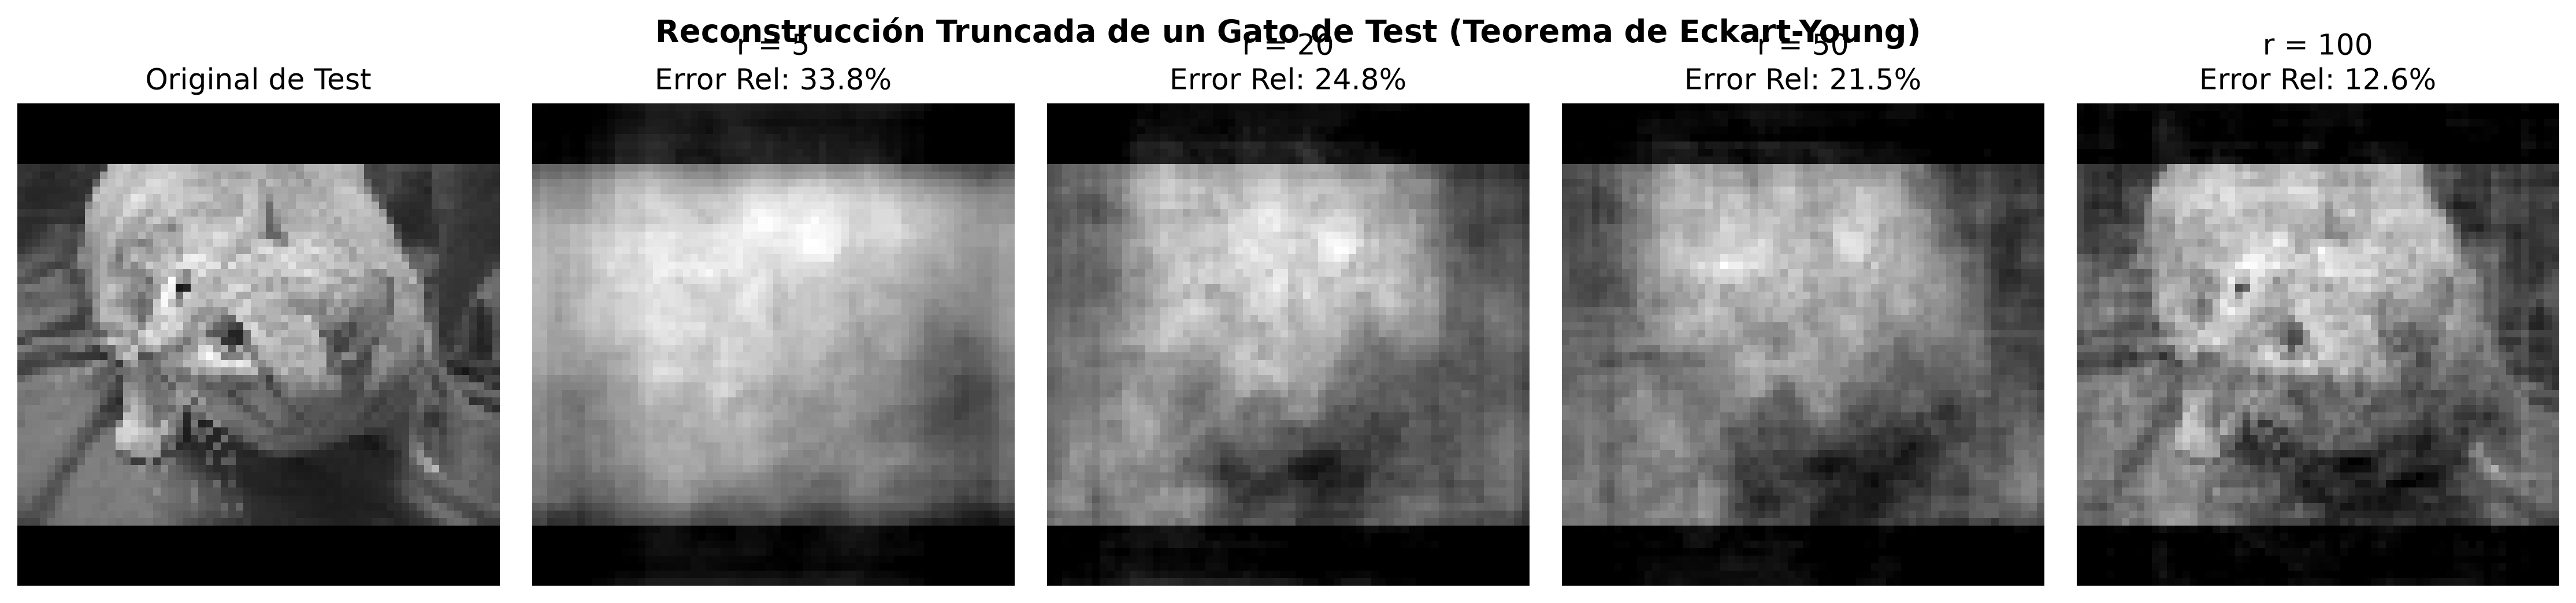

In [10]:
# Carga de imágenes en escala de grises 64x64
g_files = sorted([f for f in os.listdir(os.path.join(PROCESSED_DIR, "gatos")) if f.endswith(".jpg")])
p_files = sorted([f for f in os.listdir(os.path.join(PROCESSED_DIR, "perros")) if f.endswith(".jpg")])

cats_64 = [cv2.resize(cv2.imread(os.path.join(PROCESSED_DIR, "gatos", f), cv2.IMREAD_GRAYSCALE), (64, 64)) for f in g_files[:144]]
dogs_64 = [cv2.resize(cv2.imread(os.path.join(PROCESSED_DIR, "perros", f), cv2.IMREAD_GRAYSCALE), (64, 64)) for f in p_files[:144]]

M_cats = np.column_stack([img.flatten().astype(np.float64)/255.0 for img in cats_64])
M_dogs = np.column_stack([img.flatten().astype(np.float64)/255.0 for img in dogs_64])

mean_cat_img = M_cats.mean(axis=1, keepdims=True)
mean_dog_img = M_dogs.mean(axis=1, keepdims=True)

U_c_img, _, _ = np.linalg.svd(M_cats - mean_cat_img, full_matrices=False)
U_d_img, _, _ = np.linalg.svd(M_dogs - mean_dog_img, full_matrices=False)

# Visualización Animal Medio + Top 3 Eigen-Animals
fig, axs = plt.subplots(2, 4, figsize=(12, 6), dpi=300)

axs[0, 0].imshow(mean_cat_img.reshape(64, 64), cmap='gray'); axs[0, 0].set_title('Gato Medio'); axs[0, 0].axis('off')
for i in range(1, 4):
    axs[0, i].imshow(U_c_img[:, i-1].reshape(64, 64), cmap='gray')
    axs[0, i].set_title(f'EigenGato {i}'); axs[0, i].axis('off')

axs[1, 0].imshow(mean_dog_img.reshape(64, 64), cmap='gray'); axs[1, 0].set_title('Perro Medio'); axs[1, 0].axis('off')
for i in range(1, 4):
    axs[1, i].imshow(U_d_img[:, i-1].reshape(64, 64), cmap='gray')
    axs[1, i].set_title(f'EigenPerro {i}'); axs[1, i].axis('off')

plt.suptitle('Animales Medios y Componentes Base (Eigen-Animals estilo Clase 8)', fontsize=13, fontweight='bold')
plt.tight_layout()

eigen_out = os.path.join(MODELS_DIR, "svd_eigen_animals.png")
plt.savefig(eigen_out, bbox_inches='tight')
print(f"Eigen-Animals guardados en: {eigen_out}")
plt.show()

# Reconstrucción truncada con error relativo de Frobenius (Clase 8 Sec 1.6)
sample_cat = cv2.resize(cv2.imread(os.path.join(PROCESSED_DIR, "gatos", g_files[150]), cv2.IMREAD_GRAYSCALE), (64, 64)).flatten().astype(np.float64)/255.0
sample_cat = sample_cat[:, np.newaxis]
sample_centrado = sample_cat - mean_cat_img

r_vals = [5, 20, 50, 100]
fig, axs = plt.subplots(1, len(r_vals) + 1, figsize=(15, 3.5), dpi=300)

axs[0].imshow(sample_cat.reshape(64, 64), cmap='gray'); axs[0].set_title('Original de Test'); axs[0].axis('off')
for i, r in enumerate(r_vals):
    pesos = U_c_img[:, :r].T @ sample_centrado
    rec = mean_cat_img + U_c_img[:, :r] @ pesos
    err = np.linalg.norm(sample_cat - rec) / np.linalg.norm(sample_cat) * 100
    axs[i+1].imshow(np.clip(rec.reshape(64, 64), 0, 1), cmap='gray')
    axs[i+1].set_title(f'r = {r}\nError Rel: {err:.1f}%')
    axs[i+1].axis('off')

plt.suptitle('Reconstrucción Truncada de un Gato de Test (Teorema de Eckart-Young)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 7. Implementación de la Clase `SVDSubspaceClassifier`

Definimos formalmente el estimador de Scikit-Learn:
1. `fit(X, y)`: Centra y obtiene las bases ortonormales $\mathbf{U}_{cat}^{(r)}$ y $\mathbf{U}_{dog}^{(r)}$.
2. `compute_residuals(X)`: Proyecta y resta para calcular la norma euclidiana del error residual.
3. `predict(X)`: Asigna la clase con la **menor norma residual** $\arg\min \|\mathbf{e}\|_2$.
4. `predict_proba(X)`: Convierte las distancias en probabilidades calibradas mediante Softmax.

In [11]:
class SVDSubspaceClassifier(BaseEstimator, ClassifierMixin):
    """
    Clasificador de Subespacios SVD (Subspace Method / Menor Norma Residual).
    """
    def __init__(self, k_components=20, temperature=0.25):
        self.k_components = k_components
        self.temperature = temperature
        self.classes_ = np.array(['gatos', 'perros'])
        
    def fit(self, X, y):
        X = np.asarray(X, dtype=np.float64)
        y = np.asarray(y)
        
        X_cat = X[y == 'gatos'] if isinstance(y[0], str) else X[y == 0]
        X_dog = X[y == 'perros'] if isinstance(y[0], str) else X[y == 1]
        
        self.mu_cat_ = np.mean(X_cat, axis=0)
        self.mu_dog_ = np.mean(X_dog, axis=0)
        
        X_cat_centered = X_cat - self.mu_cat_
        X_dog_centered = X_dog - self.mu_dog_
        
        U_c, S_c, _ = np.linalg.svd(X_cat_centered.T, full_matrices=False)
        U_d, S_d, _ = np.linalg.svd(X_dog_centered.T, full_matrices=False)
        
        k = min(self.k_components, U_c.shape[1], U_d.shape[1])
        self.U_cat_ = U_c[:, :k]
        self.U_dog_ = U_d[:, :k]
        self.k_ = k
        return self
        
    def compute_residuals(self, X):
        X = np.asarray(X, dtype=np.float64)
        norms_cat = []
        norms_dog = []
        for z in X:
            diff_cat = z - self.mu_cat_
            z_rec_cat = self.U_cat_ @ (self.U_cat_.T @ diff_cat) + self.mu_cat_
            norm_cat = np.linalg.norm(z - z_rec_cat)
            
            diff_dog = z - self.mu_dog_
            z_rec_dog = self.U_dog_ @ (self.U_dog_.T @ diff_dog) + self.mu_dog_
            norm_dog = np.linalg.norm(z - z_rec_dog)
            
            norms_cat.append(norm_cat)
            norms_dog.append(norm_dog)
        return np.array(norms_cat), np.array(norms_dog)
        
    def predict(self, X):
        norms_cat, norms_dog = self.compute_residuals(X)
        return np.where(norms_cat < norms_dog, 0, 1)
        
    def predict_proba(self, X):
        norms_cat, norms_dog = self.compute_residuals(X)
        scale = (np.mean(norms_cat) + np.mean(norms_dog)) / 2.0 + 1e-6
        d_cat = norms_cat / scale
        d_dog = norms_dog / scale
        
        exp_cat = np.exp(-d_cat / self.temperature)
        exp_dog = np.exp(-d_dog / self.temperature)
        sum_exp = exp_cat + exp_dog
        
        p_cat = (exp_cat / sum_exp).reshape(-1, 1)
        p_dog = (exp_dog / sum_exp).reshape(-1, 1)
        return np.hstack([p_cat, p_dog])

# Registro en el modulo principal para permitir serializacion
import sys
setattr(sys.modules['__main__'], 'SVDSubspaceClassifier', SVDSubspaceClassifier)

## 8. Entrenamiento de los 4 Modelos y Benchmark Comparativo

Entrenamos y serializamos:
1. **SVD Subespacios** ($r=20$, Menor Norma).
2. **SVM con Kernel RBF** ($C=10.0, \gamma=\text{'scale'}$).
3. **XGBoost Forest** ($150$ árboles, profundidad $4$).
4. **Regresión Logística** (regularización $L_2$).

c:\Users\Carlos Benitez\miniconda3\envs\ml\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\Carlos Benitez\AppData\Local\Temp\ipykernel_5776\2640513205.py:48: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_metrics.sort_values(by="Accuracy (%)", ascending=False, inplace=True)


,Modelo,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
0,XGBoost Forest (150 Árboles),84.72,80.49,91.67,85.71
1,SVD Subespacios (Menor Norma),79.17,83.87,72.22,77.61
2,SVM (Kernel RBF),77.78,79.41,75.00,77.14
3,Regresión Logística (L2),75.00,71.43,83.33,76.92


Matrices guardadas en: D:/Materiales de Auxiliar/2. Machine Learning\models\confusion_matrices.png


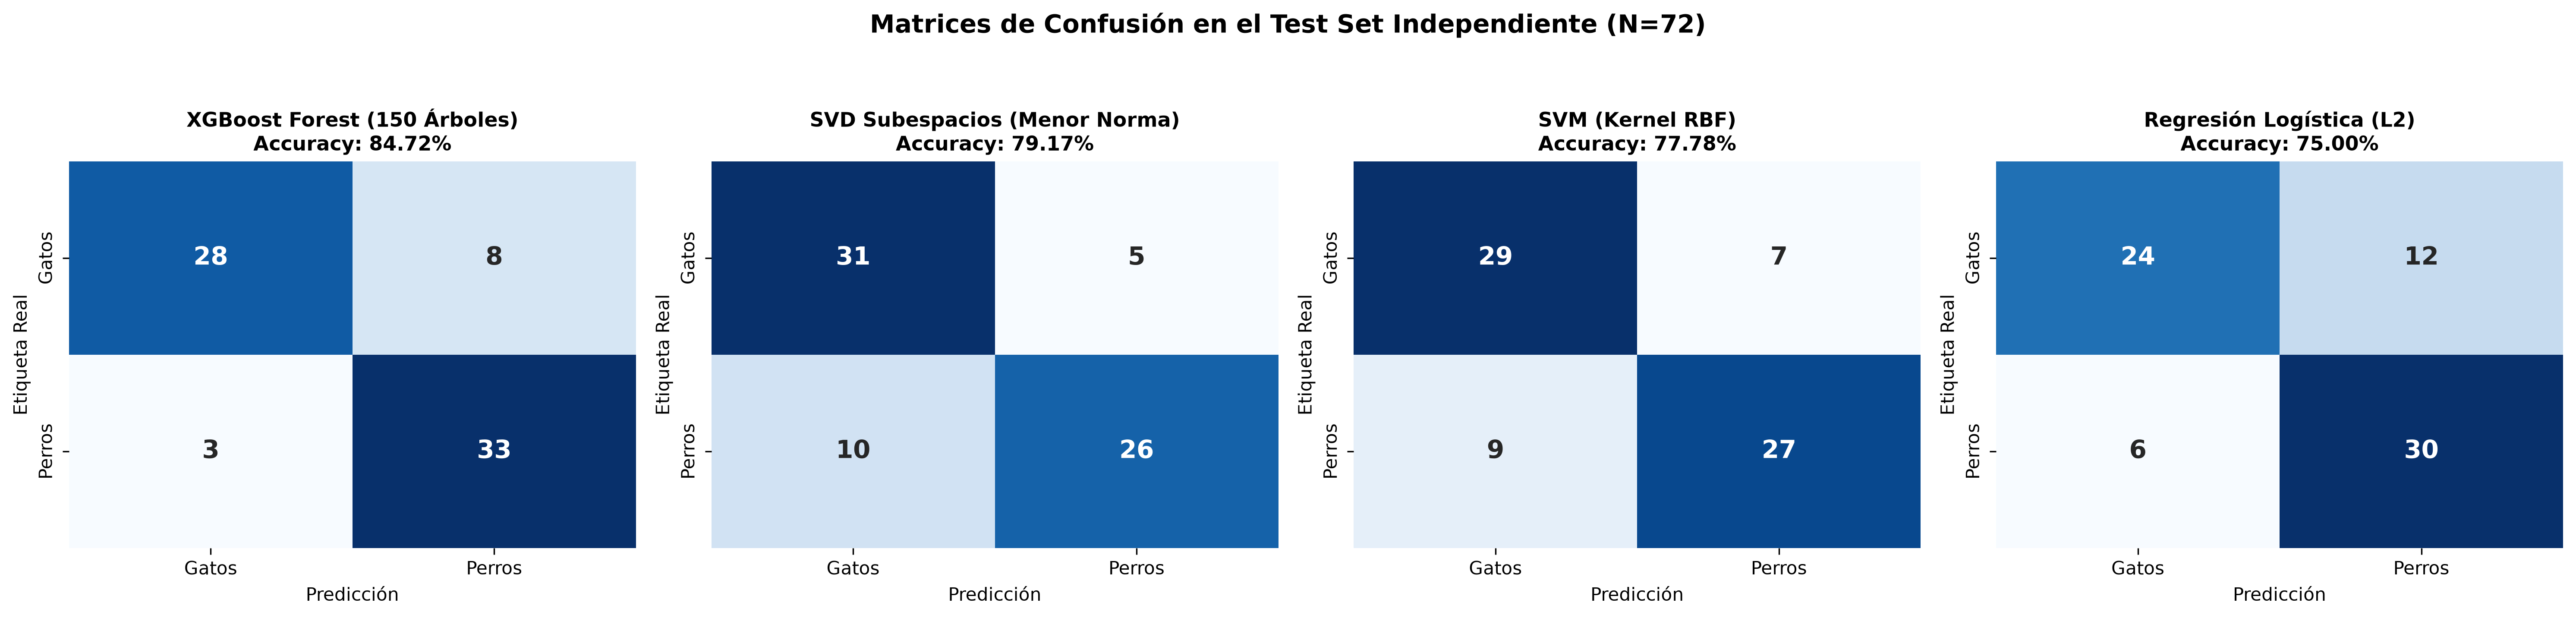

In [12]:
svd_clf = SVDSubspaceClassifier(k_components=20, temperature=0.25)
svd_clf.fit(X_train_scaled, y_train)

svm_clf = SVC(C=10.0, kernel='rbf', gamma='scale', probability=True, random_state=42)
svm_clf.fit(X_train_scaled, y_train)

xgb_clf = XGBClassifier(
    n_estimators=150, max_depth=4, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, eval_metric='logloss',
    random_state=42
)
xgb_clf.fit(X_train_scaled, y_train)

lr_clf = LogisticRegression(C=1.0, max_iter=1000, random_state=42)
lr_clf.fit(X_train_scaled, y_train)

# Serialización
joblib.dump(le, os.path.join(MODELS_DIR, "label_encoder.joblib"))
joblib.dump(scaler, os.path.join(MODELS_DIR, "scaler.joblib"))
joblib.dump(svd_clf, os.path.join(MODELS_DIR, "svd_pipeline.joblib"))
joblib.dump(svm_clf, os.path.join(MODELS_DIR, "svm_rbf.joblib"))
joblib.dump(xgb_clf, os.path.join(MODELS_DIR, "xgboost_forest.joblib"))
joblib.dump(lr_clf, os.path.join(MODELS_DIR, "logistic_regression.joblib"))

# Evaluación
models_dict = {
    "XGBoost Forest (150 Árboles)": xgb_clf,
    "SVD Subespacios (Menor Norma)": svd_clf,
    "SVM (Kernel RBF)": svm_clf,
    "Regresión Logística (L2)": lr_clf
}

metrics_summary = []
y_preds = {}

for name, clf in models_dict.items():
    preds = clf.predict(X_test_scaled)
    y_preds[name] = preds
    metrics_summary.append({
        "Modelo": name,
        "Accuracy (%)": round(accuracy_score(y_test, preds) * 100, 2),
        "Precision (%)": round(precision_score(y_test, preds, zero_division=0) * 100, 2),
        "Recall (%)": round(recall_score(y_test, preds, zero_division=0) * 100, 2),
        "F1-Score (%)": round(f1_score(y_test, preds, zero_division=0) * 100, 2)
    })

df_metrics = pd.DataFrame(metrics_summary)
df_metrics.sort_values(by="Accuracy (%)", ascending=False, inplace=True)

try:
    display(df_metrics)
except NameError:
    print(df_metrics.to_string(index=False))

# Matrices de confusión
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5), dpi=300)
for ax, (name, preds) in zip(axes, y_preds.items()):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Gatos', 'Perros'], yticklabels=['Gatos', 'Perros'],
                annot_kws={"size": 14, "weight": "bold"})
    acc_val = accuracy_score(y_test, preds) * 100
    ax.set_title(f"{name}\nAccuracy: {acc_val:.2f}%", fontsize=11, fontweight='bold')
    ax.set_ylabel("Etiqueta Real", fontsize=10)
    ax.set_xlabel("Predicción", fontsize=10)

plt.suptitle("Matrices de Confusión en el Test Set Independiente (N=72)", fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()

cm_path = os.path.join(MODELS_DIR, "confusion_matrices.png")
plt.savefig(cm_path, bbox_inches='tight')
print(f"Matrices guardadas en: {cm_path}")
plt.show()

## 9. Función de Inferencia Interactiva Directa

Para cualquier imagen nueva `.jpg`:
1. La inserta en la matriz negra $256 \times 256$ con Letterbox zero-padding.
2. Extrae las características visuales y las estandariza con el `scaler`.
3. Calcula las distancias euclidianas a los subespacios de gatos y perros:
   $$\|\mathbf{e}_{cat}\|_2 = \|\mathbf{z} - \hat{\mathbf{z}}_{cat}\|_2, \qquad \|\mathbf{e}_{dog}\|_2 = \|\mathbf{z} - \hat{\mathbf{z}}_{dog}\|_2$$
4. Asigna la clase con la **menor norma residual**.

INFERENCIA: gato_000.jpg
- Norma Residual a Subespacio Gatos: 8.6586
- Norma Residual a Subespacio Perros: 18.1490
- Decision (Menor Norma): GATOS (Delta: 9.4904)
- Confianza SVD Softmax: Gatos 94.44% | Perros 5.56%
- Prediccion SVM RBF: GATOS (97.02%)


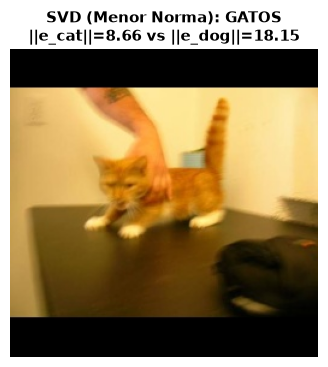

INFERENCIA: perro_000.jpg
- Norma Residual a Subespacio Gatos: 11.0753
- Norma Residual a Subespacio Perros: 9.5585
- Decision (Menor Norma): PERROS (Delta: 1.5168)
- Confianza SVD Softmax: Gatos 35.71% | Perros 64.29%
- Prediccion SVM RBF: PERROS (95.34%)


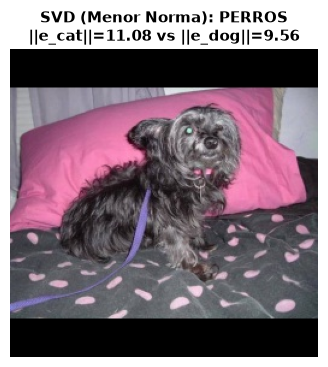

In [13]:
def insert_in_black_canvas(image_bgr, target_size=(256, 256)):
    h, w = image_bgr.shape[:2]
    target_h, target_w = target_size
    scale = min(target_w / w, target_h / h)
    new_w = max(1, int(round(w * scale)))
    new_h = max(1, int(round(h * scale)))
    interp = cv2.INTER_AREA if scale < 1.0 else cv2.INTER_CUBIC
    resized = cv2.resize(image_bgr, (new_w, new_h), interpolation=interp)
    canvas = np.zeros((target_h, target_w, 3), dtype=np.uint8)
    y_offset = (target_h - new_h) // 2
    x_offset = (target_w - new_w) // 2
    canvas[y_offset:y_offset + new_h, x_offset:x_offset + new_w] = resized
    return canvas

def compute_hog(gray_img, cell_size=32, n_bins=8):
    h, w = gray_img.shape
    gx = cv2.Sobel(gray_img, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(gray_img, cv2.CV_32F, 0, 1, ksize=3)
    mag, ang = cv2.cartToPolar(gx, gy, angleInDegrees=True)
    ang = ang % 180.0
    bin_width = 180.0 / n_bins
    bin_idx = np.floor(ang / bin_width).astype(np.int32) % n_bins
    n_cells_y = h // cell_size
    n_cells_x = w // cell_size
    hist_grid = np.zeros((n_cells_y, n_cells_x, n_bins), dtype=np.float32)
    for y in range(n_cells_y):
        for x in range(n_cells_x):
            c_mag = mag[y*cell_size:(y+1)*cell_size, x*cell_size:(x+1)*cell_size]
            c_bin = bin_idx[y*cell_size:(y+1)*cell_size, x*cell_size:(x+1)*cell_size]
            for b in range(n_bins):
                hist_grid[y, x, b] = np.sum(c_mag[c_bin == b])
    blocks = []
    for y in range(n_cells_y - 1):
        for x in range(n_cells_x - 1):
            block = hist_grid[y:y+2, x:x+2, :].flatten()
            norm = np.linalg.norm(block) + 1e-6
            blocks.append(block / norm)
    return np.concatenate(blocks) if blocks else hist_grid.flatten()

def infer_image(image_path):
    img = cv2.imread(image_path)
    if img is None:
        print(f"Error al abrir: {image_path}")
        return
        
    canvas = insert_in_black_canvas(img, (256, 256))
    canvas_rgb = cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB)
    canvas_hsv = cv2.cvtColor(canvas, cv2.COLOR_BGR2HSV)
    canvas_gray = cv2.cvtColor(canvas, cv2.COLOR_BGR2GRAY)
    
    mask = canvas_gray > 10
    if not np.any(mask): mask = np.ones_like(canvas_gray, dtype=bool)
    rgb_fg, hsv_fg = canvas_rgb[mask], canvas_hsv[mask]
    
    r_m, g_m, b_m = np.mean(rgb_fg, axis=0)
    r_s, g_s, b_s = np.std(rgb_fg, axis=0)
    h_m, s_m, v_m = np.mean(hsv_fg, axis=0)
    h_s, s_s, v_s = np.std(hsv_fg, axis=0)
    
    h_hist = cv2.calcHist([canvas_hsv], [0], mask.astype(np.uint8), [12], [0, 180]).flatten()
    s_hist = cv2.calcHist([canvas_hsv], [1], mask.astype(np.uint8), [8], [0, 256]).flatten()
    v_hist = cv2.calcHist([canvas_hsv], [2], mask.astype(np.uint8), [8], [0, 256]).flatten()
    h_hist /= (np.sum(h_hist) + 1e-6)
    s_hist /= (np.sum(s_hist) + 1e-6)
    v_hist /= (np.sum(v_hist) + 1e-6)
    
    quad_feats = {}
    h_half, w_half = 128, 128
    quad_names = ["top_left", "top_right", "bottom_left", "bottom_right"]
    coords = [(0, 0), (0, 1), (1, 0), (1, 1)]
    for name, (r, c) in zip(quad_names, coords):
        q_rgb = canvas_rgb[r*h_half:(r+1)*h_half, c*w_half:(c+1)*w_half]
        q_mask = mask[r*h_half:(r+1)*h_half, c*w_half:(c+1)*w_half]
        if np.any(q_mask):
            q_mean, q_std = np.mean(q_rgb[q_mask], axis=0), np.std(q_rgb[q_mask], axis=0)
        else:
            q_mean, q_std = [0.0, 0.0, 0.0], [0.0, 0.0, 0.0]
        quad_feats[f"{name}_r_mean"] = float(q_mean[0])
        quad_feats[f"{name}_g_mean"] = float(q_mean[1])
        quad_feats[f"{name}_b_mean"] = float(q_mean[2])
        quad_feats[f"{name}_std"] = float(np.mean(q_std))
        
    sobel_x = cv2.Sobel(canvas_gray, cv2.CV_64F, 1, 0, ksize=3)
    sobel_y = cv2.Sobel(canvas_gray, cv2.CV_64F, 0, 1, ksize=3)
    grad_mag = np.sqrt(sobel_x**2 + sobel_y**2)
    grad_mean = float(np.mean(grad_mag[mask]))
    grad_std = float(np.std(grad_mag[mask]))
    laplacian_var = float(cv2.Laplacian(canvas_gray, cv2.CV_64F).var())
    
    y_idx, x_idx = np.where(mask)
    aspect_ratio = float((np.max(x_idx) - np.min(x_idx) + 1) / (np.max(y_idx) - np.min(y_idx) + 1 + 1e-6))
    fill_ratio = float(np.sum(mask) / (256 * 256))
    
    gray_128 = cv2.resize(canvas_gray, (128, 128), interpolation=cv2.INTER_AREA)
    hog_feats = compute_hog(gray_128, cell_size=32, n_bins=8)
    
    fdict = {
        "r_mean": float(r_m), "g_mean": float(g_m), "b_mean": float(b_m),
        "r_std": float(r_s), "g_std": float(g_s), "b_std": float(b_s),
        "h_mean": float(h_m), "s_mean": float(s_m), "v_mean": float(v_m),
        "h_std": float(h_s), "s_std": float(s_s), "v_std": float(v_s),
        "grad_mean": grad_mean, "grad_std": grad_std,
        "laplacian_var": laplacian_var, "aspect_ratio": aspect_ratio, "fill_ratio": fill_ratio
    }
    for i in range(12): fdict[f"h_hist_{i}"] = float(h_hist[i])
    for i in range(8):
        fdict[f"s_hist_{i}"] = float(s_hist[i])
        fdict[f"v_hist_{i}"] = float(v_hist[i])
    fdict.update(quad_feats)
    for i, hv in enumerate(hog_feats): fdict[f"hog_{i}"] = float(hv)
    
    vec = np.array(list(fdict.values()), dtype=np.float64).reshape(1, -1)
    vec_scaled = scaler.transform(vec)
    
    norm_cat, norm_dog = svd_clf.compute_residuals(vec_scaled)
    nc, nd = norm_cat[0], norm_dog[0]
    pred_svd = "gatos" if nc < nd else "perros"
    prob_svd = svd_clf.predict_proba(vec_scaled)[0]
    
    pred_svm = le.inverse_transform(svm_clf.predict(vec_scaled))[0]
    prob_svm = svm_clf.predict_proba(vec_scaled)[0]
    
    print(f"=======================================================")
    print(f"INFERENCIA: {os.path.basename(image_path)}")
    print(f"=======================================================")
    print(f"- Norma Residual a Subespacio Gatos: {nc:.4f}")
    print(f"- Norma Residual a Subespacio Perros: {nd:.4f}")
    print(f"- Decision (Menor Norma): {pred_svd.upper()} (Delta: {abs(nd - nc):.4f})")
    print(f"- Confianza SVD Softmax: Gatos {prob_svd[0]*100:.2f}% | Perros {prob_svd[1]*100:.2f}%")
    print(f"- Prediccion SVM RBF: {pred_svm.upper()} ({np.max(prob_svm)*100:.2f}%)")
    
    plt.figure(figsize=(4, 4))
    plt.imshow(canvas_rgb)
    plt.title(f"SVD (Menor Norma): {pred_svd.upper()}\n||e_cat||={nc:.2f} vs ||e_dog||={nd:.2f}", fontsize=11, fontweight='bold')
    plt.axis('off')
    plt.show()

# Pruebas de inferencia sobre muestras de test
infer_image(os.path.join(PROCESSED_DIR, "gatos/gato_000.jpg"))
infer_image(os.path.join(PROCESSED_DIR, "perros/perro_000.jpg"))